In [2]:
import pandas as pd
import s3fs

MINIO_ENDPOINT = "http://169.58.96.176:9000"
MINIO_KEY = "admin"
MINIO_SECRET = "adminGrupo3"
BUCKET_NAME = "programacion-ciencia-datos-g3"

storage_opts = {
    "key": MINIO_KEY,
    "secret": MINIO_SECRET,
    "client_kwargs": {"endpoint_url": MINIO_ENDPOINT}
}

print("📊 Extrayendo métricas exactas para el Análisis Descriptivo (Sección 6.1)...")

# Cargar las tablas correspondientes desde la Capa Gold en MinIO
gold_tiempo = pd.read_parquet(f"s3://{BUCKET_NAME}/gold/kpis_riesgo_temporal.parquet", storage_options=storage_opts)
gold_impacto = pd.read_parquet(f"s3://{BUCKET_NAME}/gold/kpis_impacto_economico.parquet", storage_options=storage_opts)

# 1. Conteos globales
total_transacciones_global = gold_tiempo['total_tx'].sum()
total_fraudes_global = gold_tiempo['fraudes'].sum()

print(f"\n• Conteos Globales:")
print(f"  - Total Transacciones analizadas: {total_transacciones_global:,}")
print(f"  - Total Fraudes detectados: {total_fraudes_global:,}")

# 2. Promedios y Tasas
tasa_fraude_global_pct = (total_fraudes_global / total_transacciones_global) * 100
monto_total_expuesto_pen = gold_impacto['monto_total_expuesto_pen'].sum()
monto_total_perdido_pen = gold_impacto['monto_perdido_fraude_pen'].sum()
ticket_promedio_general = monto_total_expuesto_pen / total_transacciones_global

print(f"\n• Promedios y Tasas:")
print(f"  - Tasa de Fraude Global: {tasa_fraude_global_pct:.2f}%")
print(f"  - Ticket Promedio General (PEN): S/ {ticket_promedio_general:,.2f}")

# 3. Máximos y Mínimos (por franja horaria / día)
max_tasa_franja = gold_tiempo.loc[gold_tiempo['tasa_fraude_pct'].idxmax()]
min_tasa_franja = gold_tiempo.loc[gold_tiempo['tasa_fraude_pct'].idxmin()]

print(f"\n• Máximos y Mínimos:")
print(f"  - Franja con MÁXIMA tasa de fraude: {max_tasa_franja['dia_semana']} - {max_tasa_franja['franja_horaria']} ({max_tasa_franja['tasa_fraude_pct']:.2f}%)")
print(f"  - Franja con MÍNIMA tasa de fraude: {min_tasa_franja['dia_semana']} - {min_tasa_franja['franja_horaria']} ({min_tasa_franja['tasa_fraude_pct']:.2f}%)")
print(f"  - Monto total expuesto a fraude (PEN): S/ {monto_total_expuesto_pen:,.2f}")
print(f"  - Monto total perdido por fraude (PEN): S/ {monto_total_perdido_pen:,.2f}")

📊 Extrayendo métricas exactas para el Análisis Descriptivo (Sección 6.1)...

• Conteos Globales:
  - Total Transacciones analizadas: 590,540
  - Total Fraudes detectados: 20,663

• Promedios y Tasas:
  - Tasa de Fraude Global: 3.50%
  - Ticket Promedio General (PEN): S/ 506.35

• Máximos y Mínimos:
  - Franja con MÁXIMA tasa de fraude: Sunday - Mañana (06-11h) (10.70%)
  - Franja con MÍNIMA tasa de fraude: Monday - Tarde (12-17h) (2.58%)
  - Monto total expuesto a fraude (PEN): S/ 299,020,704.00
  - Monto total perdido por fraude (PEN): S/ 11,564,416.00


📈 Generando gráficas profesionales con Seaborn desde la Capa Gold...


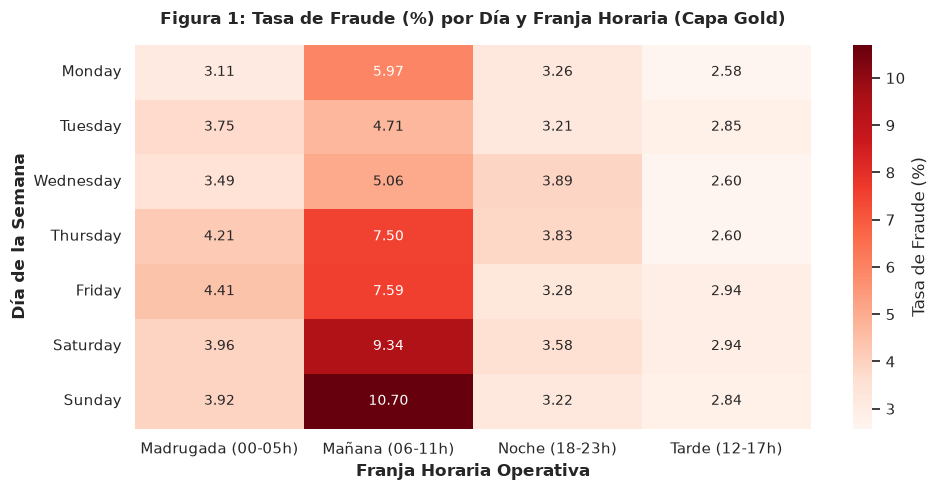

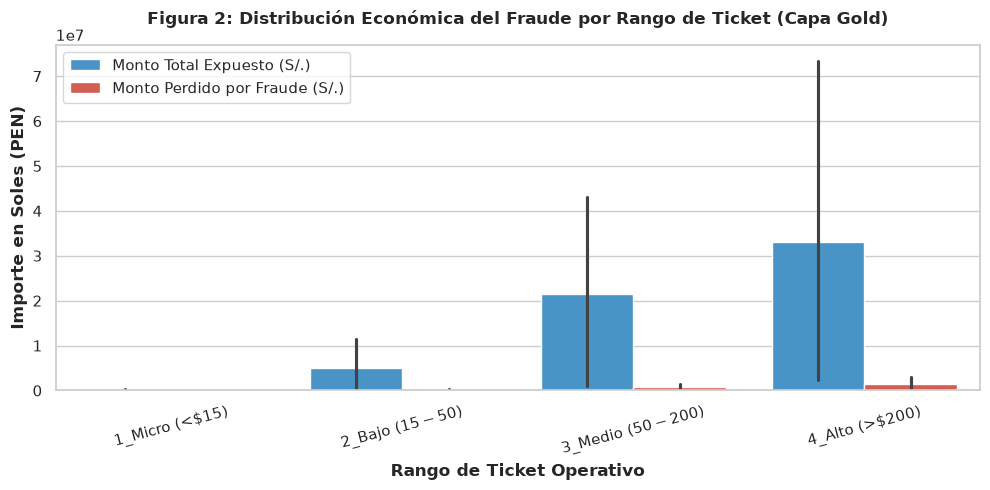

✨ ¡Gráficas de Seaborn generadas y guardadas como imágenes PNG con éxito!


In [6]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import s3fs

# Configuración de estilo visual profesional para el informe
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'figure.autolayout': True})

MINIO_ENDPOINT = "http://169.58.96.176:9000"
MINIO_KEY = "admin"
MINIO_SECRET = "adminGrupo3"
BUCKET_NAME = "programacion-ciencia-datos-g3"

storage_opts = {
    "key": MINIO_KEY,
    "secret": MINIO_SECRET,
    "client_kwargs": {"endpoint_url": MINIO_ENDPOINT}
}

print("📈 Generando gráficas profesionales con Seaborn desde la Capa Gold...")

# Cargar tablas Gold necesarias desde MinIO
gold_tiempo = pd.read_parquet(f"s3://{BUCKET_NAME}/gold/kpis_riesgo_temporal.parquet", storage_options=storage_opts)
gold_impacto = pd.read_parquet(f"s3://{BUCKET_NAME}/gold/kpis_impacto_economico.parquet", storage_options=storage_opts)

# ==============================================================================
# GRÁFICA 1: Mapa de Calor (Heatmap) - Tasa de Fraude por Día y Franja Horaria
# ==============================================================================
plt.figure(figsize=(10, 5))
pivot_temporal = gold_tiempo.pivot(index='dia_semana', columns='franja_horaria', values='tasa_fraude_pct')
dias_ordenados = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_temporal = pivot_temporal.reindex(dias_ordenados)

sns.heatmap(pivot_temporal, annot=True, fmt=".2f", cmap="Reds", cbar_kws={'label': 'Tasa de Fraude (%)'})
plt.title("Figura 1: Tasa de Fraude (%) por Día y Franja Horaria (Capa Gold)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Franja Horaria Operativa", fontweight='bold')
plt.ylabel("Día de la Semana", fontweight='bold')
plt.savefig("figura_1_riesgo_temporal.png", dpi=300)
plt.show()

# ==============================================================================
# GRÁFICA 2: Gráfico de Barras - Impacto Económico vs Exposición por Ticket
# ==============================================================================
plt.figure(figsize=(10, 5))
df_melted = gold_impacto.melt(
    id_vars='rango_ticket', 
    value_vars=['monto_total_expuesto_pen', 'monto_perdido_fraude_pen'],
    var_name='Tipo_Monto', 
    value_name='Monto_PEN'
)
df_melted['Tipo_Monto'] = df_melted['Tipo_Monto'].map({
    'monto_total_expuesto_pen': 'Monto Total Expuesto (S/.)',
    'monto_perdido_fraude_pen': 'Monto Perdido por Fraude (S/.)'
})

sns.barplot(data=df_melted, x='rango_ticket', y='Monto_PEN', hue='Tipo_Monto', palette=['#3498db', '#e74c3c'])
plt.title("Figura 2: Distribución Económica del Fraude por Rango de Ticket (Capa Gold)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Rango de Ticket Operativo", fontweight='bold')
plt.ylabel("Importe en Soles (PEN)", fontweight='bold')
plt.xticks(rotation=15)
plt.legend(title="")
plt.savefig("figura_2_impacto_economico.png", dpi=300)
plt.show()

print("✨ ¡Gráficas de Seaborn generadas y guardadas como imágenes PNG con éxito!")

📈 Generando 2 figuras adicionales de alto impacto desde la Capa Gold...


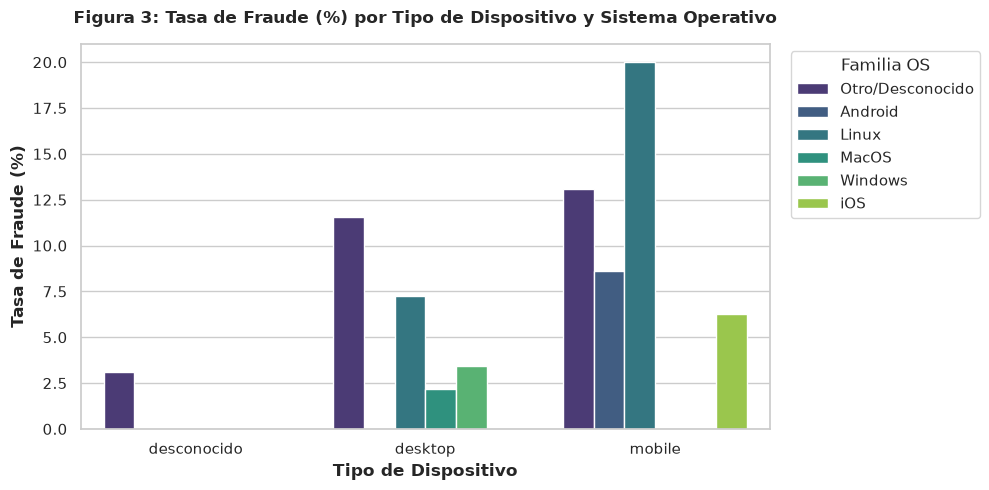

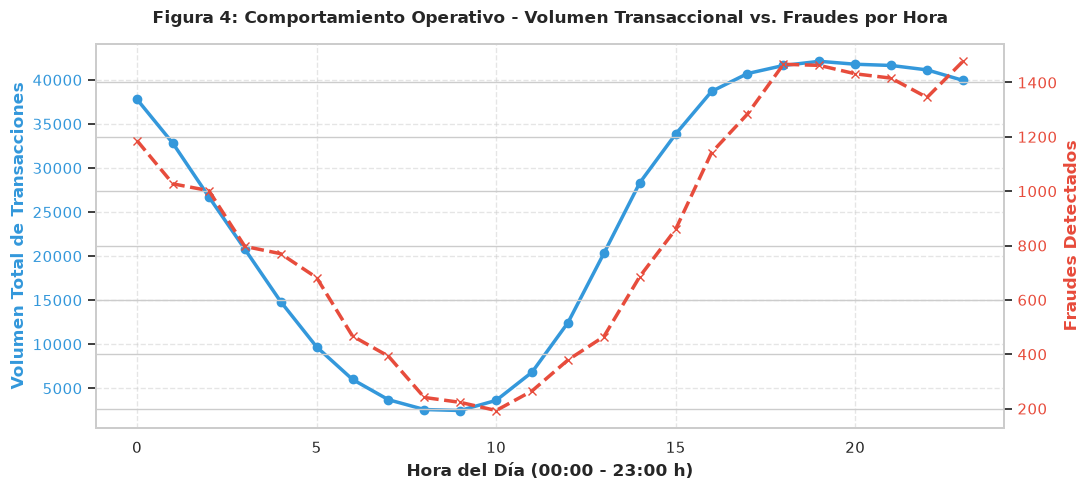

✨ ¡Figuras 3 y 4 generadas y guardadas como imágenes PNG con éxito!


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import s3fs

# Configuración de estilo visual profesional para el informe
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'figure.autolayout': True})

MINIO_ENDPOINT = "http://169.58.96.176:9000"
MINIO_KEY = "admin"
MINIO_SECRET = "adminGrupo3"
BUCKET_NAME = "programacion-ciencia-datos-g3"

storage_opts = {
    "key": MINIO_KEY,
    "secret": MINIO_SECRET,
    "client_kwargs": {"endpoint_url": MINIO_ENDPOINT}
}

print("📈 Generando 2 figuras adicionales de alto impacto desde la Capa Gold...")

# Cargar las tablas Gold correspondientes desde MinIO
gold_dispositivos = pd.read_parquet(f"s3://{BUCKET_NAME}/gold/kpis_riesgo_dispositivos.parquet", storage_options=storage_opts)
gold_velocidad = pd.read_parquet(f"s3://{BUCKET_NAME}/gold/kpis_velocidad_transaccional.parquet", storage_options=storage_opts)

# ==============================================================================
# GRÁFICA 3: Tasa de Fraude (%) por Tipo de Dispositivo y Sistema Operativo
# ==============================================================================
plt.figure(figsize=(10, 5))
sns.barplot(
    data=gold_dispositivos, 
    x='DeviceType', 
    y='tasa_fraude_pct', 
    hue='familia_os', 
    palette='viridis'
)
plt.title("Figura 3: Tasa de Fraude (%) por Tipo de Dispositivo y Sistema Operativo", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Tipo de Dispositivo", fontweight='bold')
plt.ylabel("Tasa de Fraude (%)", fontweight='bold')
plt.legend(title="Familia OS", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig("figura_3_riesgo_dispositivos.png", dpi=300, bbox_inches='tight')
plt.show()

# ==============================================================================
# GRÁFICA 4: Volumen Transaccional vs Fraudes Detectados por Hora Operativa
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(11, 5))

# Agrupar datos por hora del día
df_vel_plot = gold_velocidad.groupby('hora_dia', as_index=False)[['total_transacciones', 'fraudes_detectados']].sum()

# Eje Y izquierdo: Total de transacciones
color = '#3498db'
ax1.set_xlabel('Hora del Día (00:00 - 23:00 h)', fontweight='bold')
ax1.set_ylabel('Volumen Total de Transacciones', color=color, fontweight='bold')
ax1.plot(df_vel_plot['hora_dia'], df_vel_plot['total_transacciones'], color=color, linewidth=2.5, marker='o', label='Transacciones')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Eje Y derecho: Fraudes detectados
ax2 = ax1.twinx()  
color = '#e74c3c'
ax2.set_ylabel('Fraudes Detectados', color=color, fontweight='bold')
ax2.plot(df_vel_plot['hora_dia'], df_vel_plot['fraudes_detectados'], color=color, linewidth=2.5, linestyle='--', marker='x', label='Fraudes')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Figura 4: Comportamiento Operativo - Volumen Transaccional vs. Fraudes por Hora", fontsize=12, fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig("figura_4_velocidad_transaccional.png", dpi=300)
plt.show()

print("✨ ¡Figuras 3 y 4 generadas y guardadas como imágenes PNG con éxito!")